# Churn ClientCo – 4. Fréquence de scoring optimisée

Le pas entre deux listes (7, 14, 21 ou 28 jours) est choisi sur 20 % de clients de validation, puis mesuré sur 20 % de clients de test. Même capacité commerciale pour tous les pas. Critère : marge annuelle maximale.

In [1]:
# Se place à la racine du dépôt (dossier contenant data/)
import os, sys, json
import pandas as pd
from IPython.display import Image, display
if os.path.basename(os.getcwd()) == "modele_churn":
    os.chdir("..")
sys.path.insert(0, os.path.abspath("modele_churn"))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RES = os.path.join("modele_churn", "resultats")
print("Dossier de travail :", os.path.basename(os.getcwd()))

Dossier de travail : case_BCGX


In [2]:
PAS_JOURS = [7, 14, 21, 28]     # fréquences testées
PROFONDEURS = [5]               # [3, 5, 7] pour optimiser aussi la profondeur (plus long)
CONTACTS_PAR_MOIS = 20

In [3]:
import importlib, churn_4_frequence_optimisee as script
importlib.reload(script)
sys.argv = ["churn_4_frequence_optimisee"] + ["--pas", *map(str, PAS_JOURS), "--profondeurs", *map(str, PROFONDEURS), "--contacts-par-mois", str(CONTACTS_PAR_MOIS)]
script.main()

Cache trouvé : modele_churn\cache\agregats.pkl

== pas 7 j, profondeur 5 : 16 photos d'apprentissage, 8 listes ==
   validation : marge max 238.7 M€/an, précision 0.468, silence au contact 20.5 j

== pas 14 j, profondeur 5 : 8 photos d'apprentissage, 4 listes ==
   validation : marge max 232.7 M€/an, précision 0.456, silence au contact 18.0 j

== pas 21 j, profondeur 5 : 6 photos d'apprentissage, 3 listes ==
   validation : marge max 228.6 M€/an, précision 0.478, silence au contact 16.0 j

== pas 28 j, profondeur 5 : 4 photos d'apprentissage, 2 listes ==
   validation : marge max 227.5 M€/an, précision 0.465, silence au contact 17.0 j

  pas_jours  profondeur        jeu  contacts  precision  part_perte_captee  marge_max_an_groupe_meur  silence_median_au_contact_j
         7           5 validation       432      0.468              0.187                     238.7                         20.5
         7           5       test       432      0.514              0.223                     292

## Résultats

Fréquence retenue sur la validation : {'pas_jours': 7, 'profondeur': 5}


marge_max_an_groupe_meur            part_perte_captee            precision            silence_median_au_contact_j           
jeu                                      test validation              test validation      test validation                        test validation
pas_jours profondeur                                                                                                                             
7         5                             292.8      238.7             0.223      0.187     0.514      0.468                        15.0       20.5
14        5                             280.7      232.7             0.239      0.203     0.498      0.456                        16.0       18.0
21        5                             266.3      228.6             0.261      0.231     0.513      0.478                        16.0       16.0
28        5                             268.6      227.5             0.277      0.243     0.505      0.465                        18.0       17.0

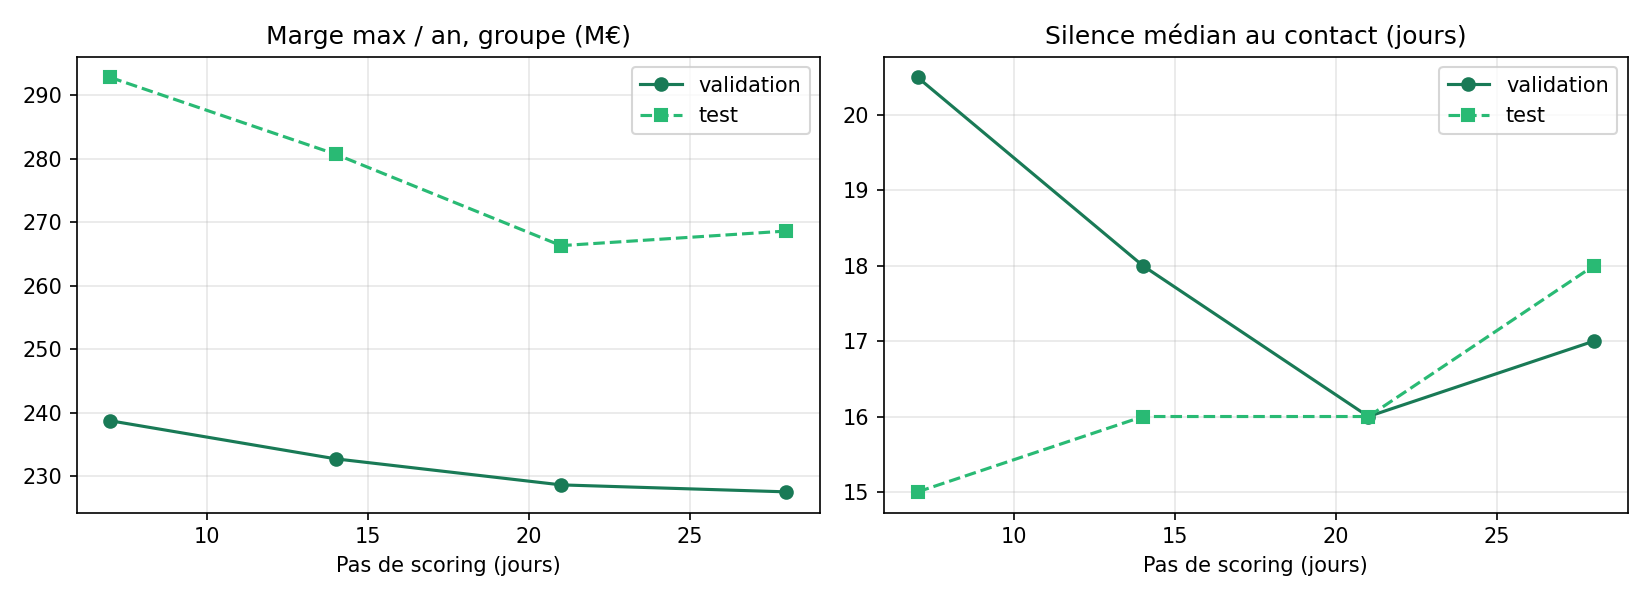

In [4]:
O = json.load(open(os.path.join(RES, "frequences", "optimisation_frequence.json"), encoding="utf-8"))
print("Fréquence retenue sur la validation :", O["choix"])
T = pd.read_csv(os.path.join(RES, "frequences", "optimisation_frequence.csv"), sep=";")
display(T.pivot_table(index=["pas_jours", "profondeur"], columns="jeu",
                      values=["marge_max_an_groupe_meur", "precision", "part_perte_captee", "silence_median_au_contact_j"]))
display(Image(os.path.join(RES, "frequences", "optimisation_frequence.png")))